# German populist candidate density by Bundesland (NUTS-1), 2002-2025

A **reusable data builder** in the same convention as `populist_vote_de_nuts1.ipynb`:
downloads the Bundeswahlleiterin's per-Wahlkreis results ("Endgültige Ergebnisse nach
Wahlkreisen aller Bundestagswahlen", `btw_kerg.zip`, Datenlizenz Deutschland BY-2.0),
derives **candidate coverage** of the PopuList parties, and writes a clean CSV of
supply-side coverage per Bundesland per Bundestagswahl. No modelling here.

## The measure

Coverage share = share of a Land's Wahlkreise in which a party fielded a **direct
candidate** (Erststimme). A party can only receive Erststimmen where it has a candidate
on the ballot, so `Erststimmen > 0` identifies candidate presence mechanically from the
official result files -- no candidate lists to parse. The measure is the *extensive
margin* of supply: bounded [0, 1], region-size-neutral (unlike absolute counts), and
varying strongly within regions over time (unlike latent trust).

Two honest limitations, stated up front:

- **Saturation**: once a party fields candidates everywhere, the measure carries no
  further signal. For the AfD the informative window is 2013-2017; from 2017 on it
  reads ~1 almost everywhere. Coverage captures the *build-out* of supply, not the
  quality of presence afterwards.
- **Family mean**: `coverage_populist` averages the PopuList parties *standing that
  year* (AfD from 2013, BSW from 2025, Die Linke and Republikaner throughout their
  runs). Before 2013 this mean mixes one near-fully-covering party (Linke/PDS ~1.0)
  with one sparse party (Republikaner ~0.05), so a value near 0.5 is "one full + one
  absent", not "half supply" -- read per-party columns for interpretation.


In [1]:
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)
KERG_ZIP = CACHE_DIR / "btw_kerg.zip"
KERG_DIR = CACHE_DIR / "btw_kerg_all"

# dam/jcr paths contain an unguessable UUID (same caveat as in
# populist_vote_de_nuts1.ipynb); if the link rots, the files sit in cache/.
KERG_URL = (
    "https://www.bundeswahlleiterin.de/dam/jcr/ce2d2b6a-f211-4355-8eea-355c98cd4e47/btw_kerg.zip"
)

if not KERG_DIR.exists():
    if not KERG_ZIP.exists():
        KERG_ZIP.write_bytes(urllib.request.urlopen(KERG_URL).read())
    with zipfile.ZipFile(KERG_ZIP) as z:
        z.extractall(KERG_DIR)

# The seven Bundestagswahlen of the trust-populism panel (2002-2025).
YEARS = {
    2002: "btw2002_kerg.csv",
    2005: "btw2005_kerg.csv",
    2009: "btw2009_kerg.csv",
    2013: "btw2013_kerg.csv",
    2017: "btw2017_kerg.csv",
    2021: "btw2021_kerg.csv",
    2025: "btw2025_kerg.csv",
}
print(sorted(p.name for p in KERG_DIR.iterdir())[:5], "...")

['btw1949_kerg.csv', 'btw1953_kerg.csv', 'btw1957_kerg.csv', 'btw1961_kerg.csv', 'btw1965_kerg.csv'] ...


## Parsing the kerg files

Three format generations, handled explicitly (assertions, no guessing): 2002 uses
2-column party blocks (Erst-/Zweitstimmen) and Land codes 901-916; 2005-2013 uses
4-column blocks (with Vorperiode) and Land codes 1-16; 2017-2025 additionally numbers
the Land rows 1-16 themselves. In every file the Land rows carry `gehört zu == 99` and
give their own code-to-name map -- the parser derives the mapping from the file rather
than assuming an ordering (the Land numbering changed across generations). Party names
are matched via an explicit per-year alias table, not fuzzy matching: PDS -> Die Linke
-> (BSW split), AfD from 2013, Republikaner standing only through 2013.

In [2]:
# PopuList parties (same classification as populist_vote_de_nuts1.csv):
# year -> exact column name in that year's kerg file; absent = party did not run.
ALIASES = {
    "AfD": {
        2013: "AfD",
        2017: "Alternative für Deutschland",
        2021: "Alternative für Deutschland",
        2025: "Alternative für Deutschland",
    },
    "Linke": {
        2002: "PDS",
        2005: "Die Linke.",
        2009: "DIE LINKE",
        2013: "DIE LINKE",
        2017: "DIE LINKE",
        2021: "DIE LINKE",
        2025: "Die Linke",
    },
    "Republikaner": {2002: "REP", 2005: "REP", 2009: "REP", 2013: "REP"},
    "BSW": {2025: "Bündnis Sahra Wagenknecht - Vernunft und Gerechtigkeit"},
}
# Validation parties: CDU/CSU and SPD must have a candidate in essentially every
# constituency -- any deviation is a parsing bug, not politics.
VAL_ALIASES = {
    "SPD": {
        2002: "SPD",
        2005: "SPD",
        2009: "SPD",
        2013: "SPD",
        2017: "Sozialdemokratische Partei Deutschlands",
        2021: "Sozialdemokratische Partei Deutschlands",
        2025: "Sozialdemokratische Partei Deutschlands",
    },
    "CDU": {
        2002: "CDU",
        2005: "CDU",
        2009: "CDU",
        2013: "CDU",
        2017: "Christlich Demokratische Union Deutschlands",
        2021: "Christlich Demokratische Union Deutschlands",
        2025: "Christlich Demokratische Union Deutschlands",
    },
    "CSU": {
        2002: "CSU",
        2005: "CSU",
        2009: "CSU",
        2013: "CSU",
        2017: "Christlich-Soziale Union in Bayern e.V.",
        2021: "Christlich-Soziale Union in Bayern e.V.",
        2025: "Christlich-Soziale Union in Bayern e.V.",
    },
}

LANDS = [
    "Schleswig-Holstein",
    "Hamburg",
    "Niedersachsen",
    "Bremen",
    "Nordrhein-Westfalen",
    "Hessen",
    "Rheinland-Pfalz",
    "Baden-Württemberg",
    "Bayern",
    "Saarland",
    "Berlin",
    "Brandenburg",
    "Mecklenburg-Vorpommern",
    "Sachsen",
    "Sachsen-Anhalt",
    "Thüringen",
]
NUTS = {
    "Baden-Württemberg": "DE1",
    "Bayern": "DE2",
    "Berlin": "DE3",
    "Brandenburg": "DE4",
    "Bremen": "DE5",
    "Hamburg": "DE6",
    "Hessen": "DE7",
    "Mecklenburg-Vorpommern": "DE8",
    "Niedersachsen": "DE9",
    "Nordrhein-Westfalen": "DEA",
    "Rheinland-Pfalz": "DEB",
    "Saarland": "DEC",
    "Sachsen": "DED",
    "Sachsen-Anhalt": "DEE",
    "Schleswig-Holstein": "DEF",
    "Thüringen": "DEG",
}
EW = {
    **{
        l: "West"
        for l in [
            "Schleswig-Holstein",
            "Hamburg",
            "Niedersachsen",
            "Bremen",
            "Nordrhein-Westfalen",
            "Hessen",
            "Rheinland-Pfalz",
            "Baden-Württemberg",
            "Bayern",
            "Saarland",
        ]
    },
    **{
        l: "East"
        for l in ["Brandenburg", "Mecklenburg-Vorpommern", "Sachsen", "Sachsen-Anhalt", "Thüringen"]
    },
    "Berlin": "Berlin",
}


def norm(s):
    return s.strip().lstrip("0") or "0"


def parse_kerg(path, year):
    """One kerg file -> (Wahlkreis rows, Land code->name map). Asserts structure."""
    raw = path.read_bytes()
    try:
        text = raw.decode("utf-8-sig")
    except UnicodeDecodeError:
        text = raw.decode("cp1252")
    lines = text.splitlines()

    # party-name header row -> per-party column index
    hdr = next(l for l in lines if l.startswith("Nr;") or l.startswith("Wahlkreis;"))
    fields = hdr.split(";")
    party_col = {}
    if year == 2002:
        # names appear in identical pairs (Erststimmen;Zweitstimmen per party)
        i = 0
        while i < len(fields) - 1:
            if (
                fields[i]
                and fields[i] == fields[i + 1]
                and fields[i] not in ("Ungültige", "Gültige")
            ):
                party_col[fields[i]] = i
                i += 2
            else:
                i += 1
    else:
        # names appear once at each 4-column block start
        # (Erst_Endgültig, Erst_Vorperiode, Zweit_Endgültig, Zweit_Vorperiode)
        admin = {
            "Nr",
            "Gebiet",
            "gehört",
            "zu",
            "gehört zu",
            "Gewählt",
            "Wahlberechtigte",
            "Wähler",
            "Wählende",
            "Ungültige",
            "Ungültige Stimmen",
            "Gültige",
            "Gültige Stimmen",
        }
        for i, f in enumerate(fields):
            if f and f not in admin and f not in party_col:
                party_col[f] = i

    land_code_to_name, rows = {}, []
    for l in lines:
        if l.startswith("#") or not l.strip():
            continue
        fs = [x.strip() for x in l.split(";")]
        if len(fs) < 5 or not fs[0].strip('"').isdigit():
            continue
        nr, name, gehoert = norm(fs[0]), fs[1].strip('"'), (fs[2] if len(fs) > 2 else "")
        if int(nr) >= 900 or gehoert == "99":
            if name in LANDS:  # Land row: derive the file's own code->name map
                key = norm(nr[1:]) if year in (2005, 2009, 2013) else norm(nr)
                land_code_to_name[key] = name
            continue  # Bundesgebiet
        if 1 <= int(nr) <= 299 and gehoert and gehoert != "99":
            present = {}
            for party, per_year in {**ALIASES, **VAL_ALIASES}.items():
                col = party_col.get(per_year.get(year, ""))
                if col is None:
                    continue
                try:
                    present[party] = int(fs[col]) > 0
                except (ValueError, IndexError):
                    present[party] = False
            rows.append((int(nr), norm(gehoert), present))

    assert len(rows) == 299, f"{year}: {len(rows)} constituency rows, expected 299"
    assert len(land_code_to_name) == 16, f"{year}: {len(land_code_to_name)} Laender rows"
    assert not set(land_code_to_name.values()) ^ set(LANDS), f"{year}: unexpected Laender"
    codes = {c for _, c, _ in rows}
    assert codes <= set(land_code_to_name), f"{year}: unknown Land codes"
    return rows, land_code_to_name


all_rows = []
for year, fname in sorted(YEARS.items()):
    rows, land_map = parse_kerg(KERG_DIR / fname, year)
    for wkr_nr, land_code, present in rows:
        all_rows.append(
            {
                "year": year,
                "wkr_nr": wkr_nr,
                "regionname": land_map[land_code],
                **{f"present_{p}": v for p, v in present.items()},
            }
        )
wkr = pd.DataFrame(all_rows)
print(wkr.shape)

(2093, 10)


## Validation before trusting anything downstream

Hard facts the parse must reproduce: SPD has a direct candidate in every constituency
in every election; CDU and CSU are mutually exclusive and jointly exhaustive; no AfD
before 2013, no BSW before 2025, no Republikaner after 2013. And the output grid must
match the existing vote CSV exactly (same Länder, same NUTS codes).

In [3]:
assert (wkr.loc[wkr.year < 2013, "present_AfD"].fillna(False) == False).all()
assert wkr.loc[wkr.year >= 2013, "present_AfD"].any()
assert (wkr.loc[wkr.year < 2025, "present_BSW"].fillna(False) == False).all()
assert (wkr.loc[wkr.year >= 2017, "present_Republikaner"].fillna(False) == False).all()
for (year, land), g in wkr.groupby(["year", "regionname"]):
    cdu, csu = g.present_CDU.fillna(False), g.present_CSU.fillna(False)
    assert not (cdu.any() and csu.any()), f"{year} {land}: CDU and CSU both ran"
    assert cdu.any() or csu.any(), f"{year} {land}: no CDU/CSU candidate"
spd_cov = wkr.groupby(["year", "regionname"])["present_SPD"].mean()
assert (spd_cov == 1.0).all(), "SPD coverage below 1.0 -- parsing bug"
print("all Wahlkreis-level checks passed")

# the output grid must agree with populist_vote_de_nuts1.csv (same Länder, NUTS codes)
vote = pd.read_csv("populist_vote_de_nuts1.csv")
land_to_nuts = dict(zip(vote.regionname, vote.nuts_code))
assert all(NUTS[l] == land_to_nuts[l] for l in LANDS), "NUTS codes disagree with vote CSV"
print("NUTS mapping consistent with populist_vote_de_nuts1.csv")

all Wahlkreis-level checks passed
NUTS mapping consistent with populist_vote_de_nuts1.csv


## Building the reusable CSV

One row per (election year, Bundesland): number of Wahlkreise, per-party coverage share,
family mean over the PopuList parties standing that year, and the East/West tag.

In [4]:
agg = wkr.groupby(["year", "regionname"], sort=True).agg(n_wahlkreise=("wkr_nr", "size"))
for p in ALIASES:
    agg[f"coverage_{p}"] = wkr.groupby(["year", "regionname"], sort=True)[f"present_{p}"].mean()
agg = agg.reset_index()
party_cols = [f"coverage_{p}" for p in ALIASES]
agg["coverage_populist"] = agg[party_cols].mean(axis=1, skipna=True)
agg["nuts_code"] = agg["regionname"].map(NUTS)
agg["ew"] = agg["regionname"].map(EW)
agg = (
    agg[
        ["year", "nuts_code", "regionname", "n_wahlkreise"]
        + party_cols
        + ["coverage_populist", "ew"]
    ]
    .sort_values(["year", "nuts_code"])
    .reset_index(drop=True)
)

# every (year, Land) must exist in the vote panel's grid
known = set(zip(vote.year, vote.regionname))
assert set(zip(agg.year, agg.regionname)) <= known, "rows outside the vote panel grid"

agg.to_csv("candidate_density_de_nuts1.csv", index=False)
print(agg.groupby("year")[party_cols + ["coverage_populist"]].mean().round(3).to_string())

     coverage_AfD  coverage_Linke coverage_Republikaner coverage_BSW coverage_populist
year                                                                                  
2002          NaN           0.948              0.046724          NaN            0.4972
2005          NaN           0.977               0.04825          NaN          0.512749
2009          NaN           0.998              0.031647          NaN          0.514847
2013     0.528941           0.999              0.045819          NaN          0.524595
2017     0.972239           0.994                   NaN          NaN          0.983279
2021     0.990056           0.993                   NaN          NaN          0.991777
2025     0.995387           0.997                   NaN     0.159969          0.717432


## Coverage over time, East vs West

The supply story the measure captures: the PDS starts fully covering the East in 2002
while western coverage builds slowly (BW 0.84, BY 0.73, RP 0.67); the AfD ramps from
0.53 (2013) to 0.97 (2017) and saturates; the BSW enters 2025 patchy (Thüringen full,
five Länder at zero). Note how the East/West coverage gap is *gone* by 2017 even though
the vote gap kept widening -- direct-candidate coverage measures the build-out of
supply, not its intensity.

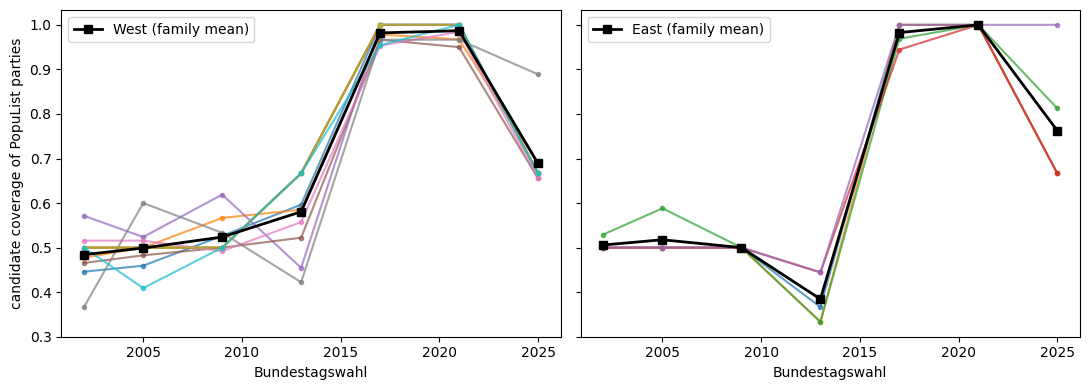

In [5]:
REGION_COLORS = {"West": "#1f77b4", "East": "#d62728", "Berlin": "#7f7f7f"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for reg, ax in [("West", ax1), ("East", ax2)]:
    sub = agg[agg.ew == reg]
    for land, g in sub.groupby("regionname"):
        g = g.sort_values("year")
        ax.plot(g.year, g.coverage_populist, "-o", ms=3, alpha=0.7)
    fam = sub.groupby("year").apply(lambda g: g[party_cols].mean().mean(), include_groups=False)
    ax.plot(fam.index, fam.values, "s-", color="black", lw=2, label=f"{reg} (family mean)")
    ax.set_xlabel("Bundestagswahl")
    ax.legend()
ax1.set_ylabel("candidate coverage of PopuList parties")
plt.tight_layout()
plt.show()